# Matched hybrid versus linear feedback: successes and failures

This notebook reads completed E1 operating-region results only. **H** is the submitted hybrid planner/feedback controller; **L** is its data-fitted linear feedback used alone. No controller, training or simulation runs here.

Primary success means angle within ±0.02 rad and physical angular speed within ±0.05 rad/s throughout the last three seconds, with no earlier fall (|angle| ≥ π/2). Cart travel/rest are descriptive, not additional acceptance gates. Each pair shares the model/data seed and exact initial state. All examples last 14 seconds.

Plots and playback data below are embedded for reading without the raw archive. Running cells or browsing another case requires NumPy, Matplotlib and the local saved trajectories. Browser playback needs a trusted notebook; static plots remain available if scripts are blocked.

See the [collaborator brief](../results_v1/COLLABORATOR_BRIEF.md), [full report](../results_v1/RESULTS.md) and [initial-state maps](../results_v1/briefing_figures/initial_state_regimes.png). The older [Gate A source notebook](gate_a_examples_source.ipynb) is historical true-model evidence, not this matched H/L comparison.

In [1]:

import ast, csv, json, uuid
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display

# Resolve the project from the notebook directory or project/workspace root.
PROJECT = next((q for p in [Path.cwd(), *Path.cwd().parents]
                for q in [p, p / 'TrajectoryManifoldControl']
                if (q / 'validation/results_v1/E1/summary.csv').exists()), None)
if PROJECT is None:
    raise FileNotFoundError('Open from the project or validation/notebooks directory, with the saved result archive present.')
ROWS = list(csv.DictReader((PROJECT / 'validation/results_v1/E1/summary.csv').open()))

def paired_cases(seed=0, ic_set='C'):
    pairs = {}
    for r in ROWS:
        if r['arm'] in ['H', 'L'] and int(r['seed']) == seed and r['ic_set'] == ic_set and float(r['seconds']) == 14:
            pairs.setdefault(int(r['ic_index']), {})[r['arm']] = r
    assert all(set(p) == {'H', 'L'} for p in pairs.values())
    for p in pairs.values():
        assert p['H']['initial_state'] == p['L']['initial_state']
    return pairs

def load_pair(seed, ic_set, index):
    pair = paired_cases(seed, ic_set)[index]
    arrays = {}
    for arm, r in pair.items():
        path = PROJECT / r['raw_path']
        if not path.exists():
            raise FileNotFoundError(f'Missing local trajectory: {path}. Embedded examples remain readable; rebuilding requires the raw archive.')
        with np.load(path, allow_pickle=False) as z:
            arrays[arm] = {k: z[k].copy() for k in ['t', 'X', 'U']}
        a = arrays[arm]; tail = a['t'] >= a['t'][-1] - 3
        balanced = bool(np.all(np.abs(a['X'][tail, 2]) <= .02) and np.all(np.abs(a['X'][tail, 3]) * np.sqrt(9.81) <= .05))
        no_fall = bool(np.isfinite(a['X']).all() and np.isfinite(a['U']).all() and np.all(np.abs(a['X'][:, 2]) < np.pi / 2))
        assert (balanced and no_fall) == (r['primary_success'] == 'True'), r['case']
    assert np.array_equal(arrays['H']['t'], arrays['L']['t'])
    assert np.allclose(arrays['H']['X'][0], arrays['L']['X'][0])
    return pair, arrays

def comparison_plot(seed, ic_set, index):
    pair, arrays = load_pair(seed, ic_set, index)
    fig, ax = plt.subplots(3, 2, figsize=(10, 8), layout='constrained')
    colors = {'H': '#c26832', 'L': '#16758a'}
    linestyles = {'H': '-', 'L': '--'}
    for arm, a in arrays.items():
        t, x, u = a['t'], a['X'], a['U']
        label = f"{arm}: {'success' if pair[arm]['primary_success'] == 'True' else 'failure'}"
        for axis, y in [(ax[0,0], x[:,2]), (ax[0,1], x[:,2]),
                        (ax[1,0], x[:,0]), (ax[1,1], x[:,3] * np.sqrt(9.81)),
                        (ax[2,0], x[:,1] * np.sqrt(9.81))]:
            axis.plot(t, y, color=colors[arm], label=label, lw=1.2, linestyle=linestyles[arm])
        ax[2,1].step(t[:-1], u[:,0] * 9.81, where='post', color=colors[arm], label=label, lw=1)
    ax[0,0].set_ylabel('Angle (rad)')
    ax[0,0].axhline(np.pi/2, color='gray', ls=':', lw=.7)
    ax[0,0].axhline(-np.pi/2, color='gray', ls=':', lw=.7)
    ax[0,1].set(title='Final three seconds: angle', ylabel='Angle (rad)', xlim=(11,14))
    ax[1,0].set_ylabel('Cart position (m)')
    ax[1,1].set(title='Final three seconds: angular speed', ylabel='Angular speed (rad/s)', xlim=(11,14))
    ax[2,0].set_ylabel('Cart speed (m/s)')
    ax[2,1].set_ylabel('Applied force (N)')
    for axis, bound in [(ax[0,1], .02), (ax[1,1], .05)]:
        axis.axhspan(-bound, bound, color='#8cab74', alpha=.2)
        axis.set_yscale('symlog', linthresh=bound)
    for axis in ax.ravel():
        axis.set_xlabel('Time (s)'); axis.grid(alpha=.15)
    ax[0,0].legend(fontsize=8)
    x0 = arrays['H']['X'][0]
    fig.suptitle(f'Seed {seed}, set {ic_set}, case {index:04d} | p0={x0[0]:.2f} m, '
                 f'v0={x0[1]*np.sqrt(9.81):.2f} m/s, angle0={np.rad2deg(x0[2]):.1f} deg, '
                 f'rate0={x0[3]*np.sqrt(9.81):.2f} rad/s', fontsize=10)
    return fig

def animation_html(seed, ic_set, index):
    pair, arrays = load_pair(seed, ic_set, index)
    ident = 'pair_' + uuid.uuid4().hex
    data = {a: {'x': z['X'][:,[0,2]].tolist(), 'success': pair[a]['primary_success'] == 'True'} for a,z in arrays.items()}
    data['t'] = arrays['H']['t'].tolist()
    template = """<div id="__ID__" style="max-width:900px;border:1px solid #ddd;padding:8px">
    <div><button class="play">Play / pause</button> <button class="reset">Reset</button>
    <input class="seek" type="range" min="0" max="700" value="0" style="width:55%"> <span class="time"></span></div>
    <canvas width="900" height="250" style="width:100%;height:auto"></canvas>
    <small>Each camera follows its own cart. Position is shown numerically; the ground line is not a rail constraint.</small>
    <script>(()=>{const root=document.getElementById('__ID__'), d=__DATA__, canvas=root.querySelector('canvas'),c=canvas.getContext('2d'),seek=root.querySelector('.seek');
    let i=0,playing=false,last=null;seek.max=d.t.length-1;
    function draw(){c.clearRect(0,0,900,250);['H','L'].forEach((a,j)=>{let ox=j*450, x=d[a].x[i],theta=x[1], cx=ox+225,cy=185;
    c.fillStyle=a==='H'?'#c26832':'#16758a';c.font='17px sans-serif';c.fillText(a+': '+(d[a].success?'success':'failure'),ox+15,24);
    c.fillStyle='#333';c.font='14px sans-serif';c.fillText('Cart position '+x[0].toFixed(2)+' m | angle '+(theta*180/Math.PI).toFixed(1)+' deg',ox+15,48);
    c.strokeStyle='#bbb';c.beginPath();c.moveTo(ox+10,cy+18);c.lineTo(ox+440,cy+18);c.stroke();
    c.fillStyle=a==='H'?'#c26832':'#16758a';c.fillRect(cx-27,cy-10,54,20);
    c.strokeStyle=c.fillStyle;c.lineWidth=5;c.beginPath();c.moveTo(cx,cy);c.lineTo(cx+105*Math.sin(theta),cy-105*Math.cos(theta));c.stroke();
    c.beginPath();c.arc(cx+105*Math.sin(theta),cy-105*Math.cos(theta),7,0,Math.PI*2);c.fill();});
    seek.value=i;root.querySelector('.time').textContent=d.t[i].toFixed(2)+' s';}
    seek.oninput=()=>{i=Number(seek.value);playing=false;draw();};root.querySelector('.play').onclick=()=>{playing=!playing;last=null;};
    root.querySelector('.reset').onclick=()=>{i=0;playing=false;draw();};
    function frame(ts){if(!root.isConnected)return;if(playing){if(last===null)last=ts;let steps=Math.floor((ts-last)/20);if(steps>0){i=Math.min(i+steps,d.t.length-1);last+=steps*20;draw();if(i===d.t.length-1)playing=false;}}requestAnimationFrame(frame);}
    draw();requestAnimationFrame(frame);})();</script></div>"""
    return template.replace('__ID__', ident).replace('__DATA__', json.dumps(data, separators=(',',':')))


## All 200 random starting states

| Seed | Both succeed | L only | H only | Both fail |
|---|---:|---:|---:|---:|
| 0 | 45 | 77 | 3 | 75 |
| 1 | 31 | 99 | 0 | 70 |
| 2 | 77 | 51 | 1 | 71 |

These are counts of starting states, not index intervals. Seeds change the full collection/fitting/planning run. The same 200 states are reused across seeds. The examples below are the smallest case index in each seed-0 category, chosen deterministically rather than ranked by visual appeal. They illustrate outcomes, not their sole causes or general operating boundaries.

## Both succeed: seed 0, random-state case 0001

H: fell=False, terminal angular limits met=True | L: fell=False, terminal angular limits met=True

The shaded bands show the angular limits. Terminal panels zoom to 11–14 s and use a scale that is linear inside the tolerance band and compresses larger values; cart motion and force remain visible separately. A run may remain upright and still miss settling tolerances. Playback is schematic; the plots show physical units.

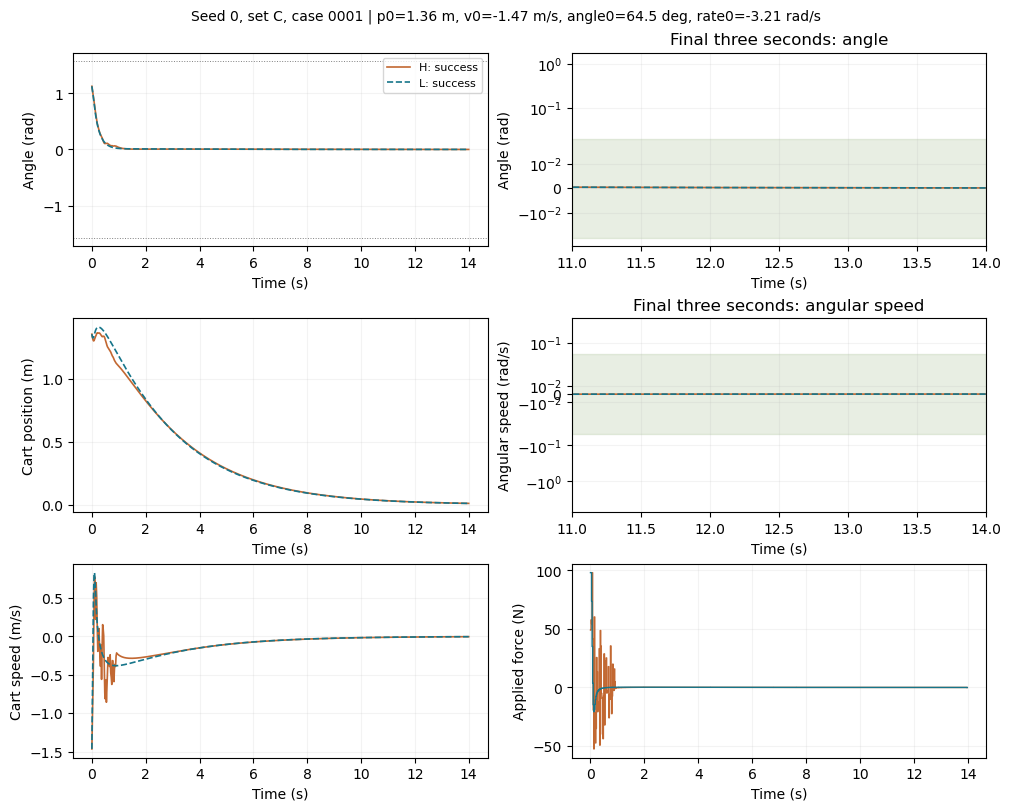

In [2]:
fig = comparison_plot(0, 'C', 1)
display(fig)
plt.close(fig)

In [3]:
display(HTML(animation_html(0, 'C', 1)))

## L succeeds; H fails: seed 0, random-state case 0000

H: fell=False, terminal angular limits met=False | L: fell=False, terminal angular limits met=True

The shaded bands show the angular limits. Terminal panels zoom to 11–14 s and use a scale that is linear inside the tolerance band and compresses larger values; cart motion and force remain visible separately. A run may remain upright and still miss settling tolerances. Playback is schematic; the plots show physical units.

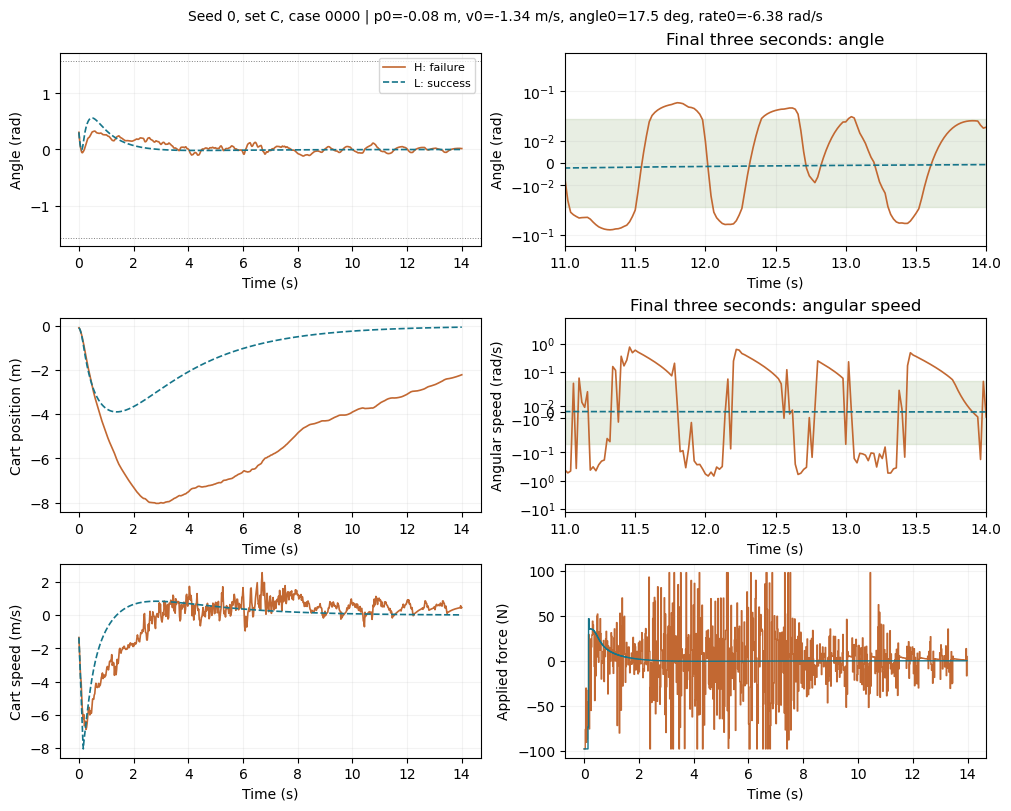

In [4]:
fig = comparison_plot(0, 'C', 0)
display(fig)
plt.close(fig)

In [5]:
display(HTML(animation_html(0, 'C', 0)))

## H succeeds; L fails: seed 0, random-state case 0034

H: fell=False, terminal angular limits met=True | L: fell=True, terminal angular limits met=False

The shaded bands show the angular limits. Terminal panels zoom to 11–14 s and use a scale that is linear inside the tolerance band and compresses larger values; cart motion and force remain visible separately. A run may remain upright and still miss settling tolerances. Playback is schematic; the plots show physical units.

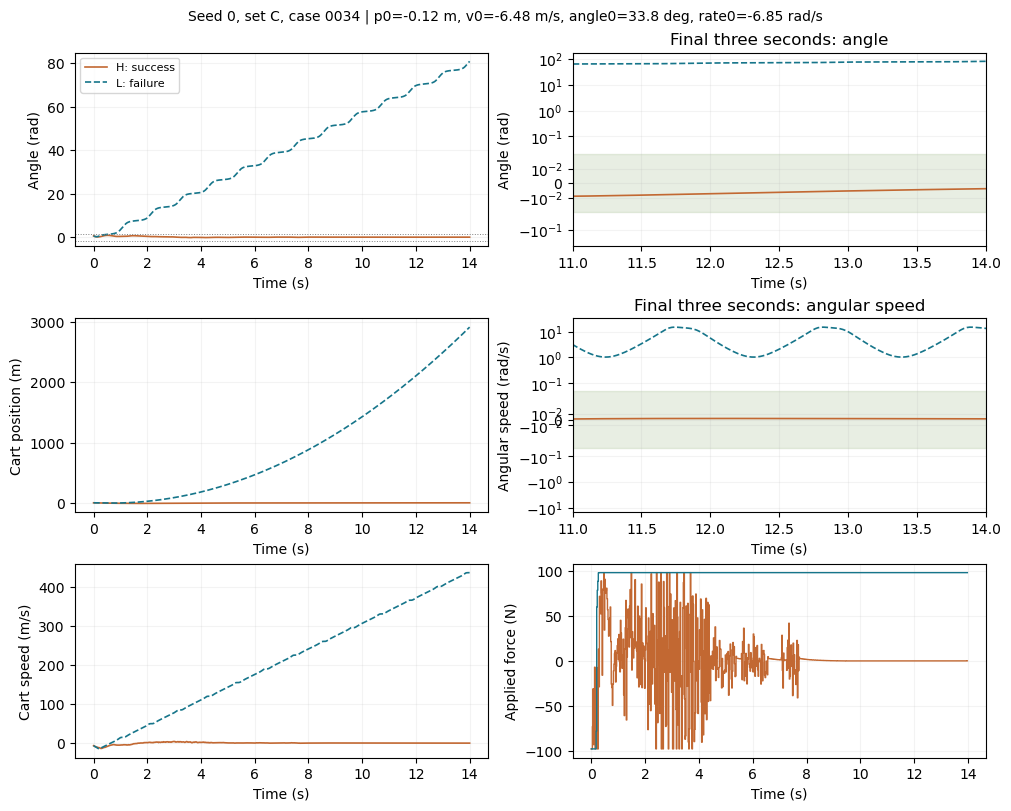

In [6]:
fig = comparison_plot(0, 'C', 34)
display(fig)
plt.close(fig)

In [7]:
display(HTML(animation_html(0, 'C', 34)))

## Both fail: seed 0, random-state case 0002

H: fell=True, terminal angular limits met=False | L: fell=True, terminal angular limits met=False

The shaded bands show the angular limits. Terminal panels zoom to 11–14 s and use a scale that is linear inside the tolerance band and compresses larger values; cart motion and force remain visible separately. A run may remain upright and still miss settling tolerances. Playback is schematic; the plots show physical units.

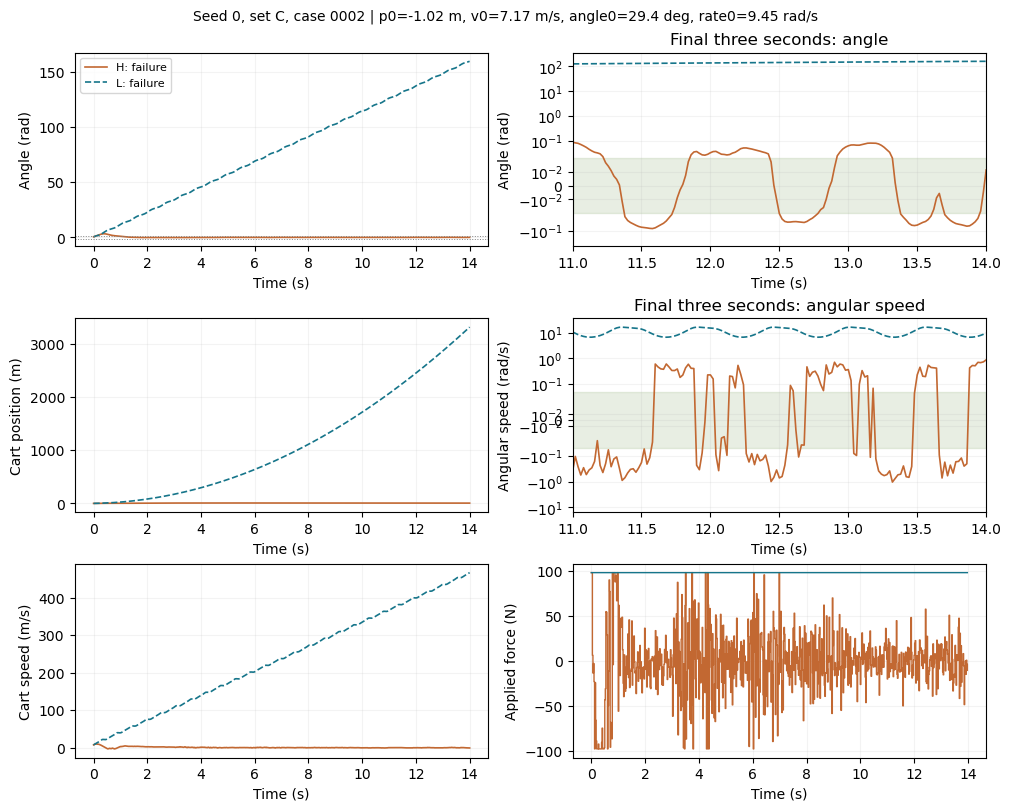

In [8]:
fig = comparison_plot(0, 'C', 2)
display(fig)
plt.close(fig)

In [9]:
display(HTML(animation_html(0, 'C', 2)))

## Browse another matched starting state

Change the seed (0–2), set (`B`: from rest, `C`: random states, `D`: angle/angular-speed grid), and index below. Selection by index is for browsing, not the success counts above. Only saved 14-second trajectories are loaded; missing local files raise a clear error. This cell has not been pre-executed.

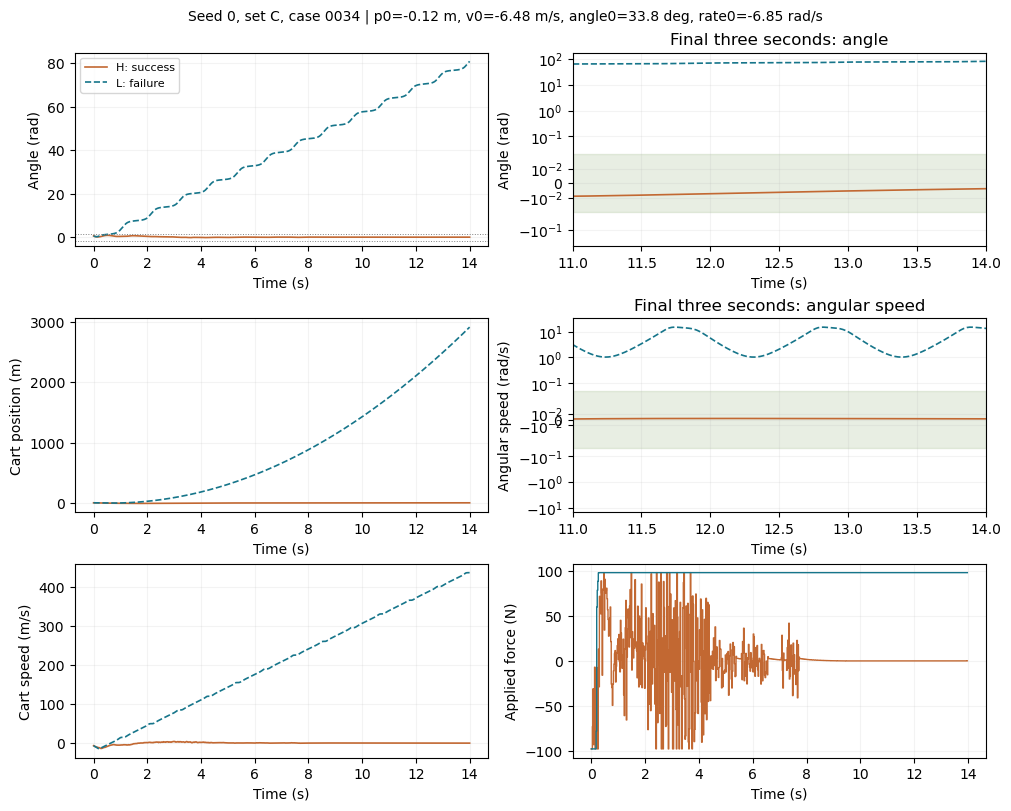

In [10]:
SEED, IC_SET, CASE_INDEX = 0, 'C', 34
fig = comparison_plot(SEED, IC_SET, CASE_INDEX)
display(fig)
plt.close(fig)
display(HTML(animation_html(SEED, IC_SET, CASE_INDEX)))

## Scope and provenance

Source: `validation/results_v1/E1/summary.csv`, matched case JSON and raw NPZ paths recorded there. The builder independently recomputes angular/no-fall endpoints for all eight illustrated trajectories and verifies matching timestamps/initial states. Velocities multiply stored coordinates by √9.81; force multiplies normalized input by 9.81 N for the submitted plant. The sampled outcomes do not certify nonlinear stability. No new scientific cases are generated.

Rebuild with `validation/experiments/build_collaborator_notebook.py --project /absolute/path/to/TrajectoryManifoldControl` in a plotting environment. Older [Gate A notebook instructions](README.md) describe a separate historical dataset and endpoint; do not mix its strict scores with this campaign.